<img src="../../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# pandas for Exploratory Data Analysis - imdb data - Solution

---

In [1]:
'''
BASIC LEVEL
'''

'\nBASIC LEVEL\n'

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
# read in 'imdb_1000.csv' and store it in a DataFrame named movies
imdb_1000_data_url = '../data/imdb_1000.csv'
movies = pd.read_csv(imdb_1000_data_url)

In [4]:
# check the number of rows and columns
movies.shape

(979, 6)

In [5]:
# check the data type of each column
movies.dtypes

star_rating       float64
title              object
content_rating     object
genre              object
duration            int64
actors_list        object
dtype: object

In [6]:
# calculate the average movie duration
movies.duration.mean()

120.97957099080695

In [7]:
# sort the DataFrame by duration to find the shortest and longest movies
movies.sort_values('duration').head(1)
movies.sort_values('duration').tail(1)

,star_rating,title,content_rating,genre,duration,actors_list
476,7.8,Hamlet,PG-13,Drama,242,"[u'Kenneth Branagh', u'Julie Christie', u'Dere..."


<Axes: ylabel='Frequency'>

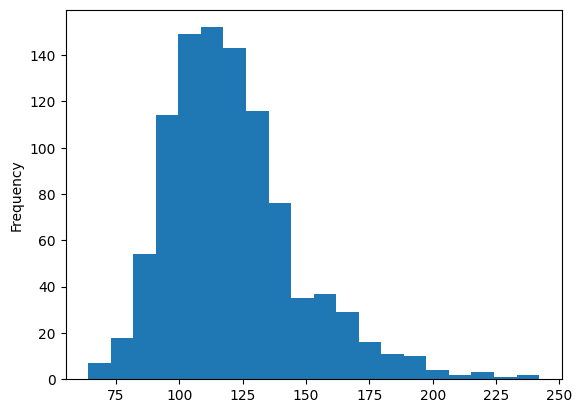

In [8]:
# create a histogram of duration, choosing an "appropriate" number of bins
movies.duration.plot(kind='hist', bins=20)

<Axes: >

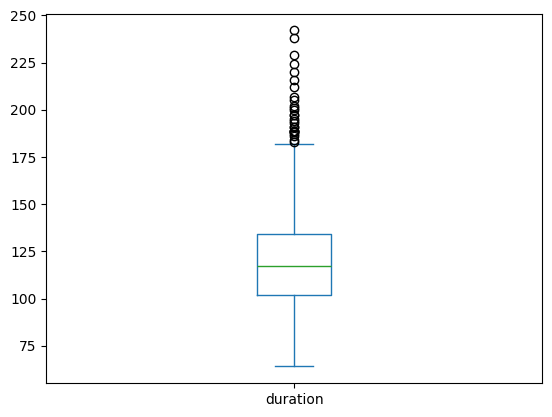

In [9]:
# use a box plot to display that same data
movies.duration.plot(kind='box')

In [10]:
'''
INTERMEDIATE LEVEL
'''

'\nINTERMEDIATE LEVEL\n'

In [11]:
# count how many movies have each of the content ratings
movies.content_rating.value_counts()

content_rating
R            460
PG-13        189
PG           123
NOT RATED     65
APPROVED      47
UNRATED       38
G             32
PASSED         7
NC-17          7
X              4
GP             3
TV-MA          1
Name: count, dtype: int64

Text(0, 0.5, 'Number of Movies')

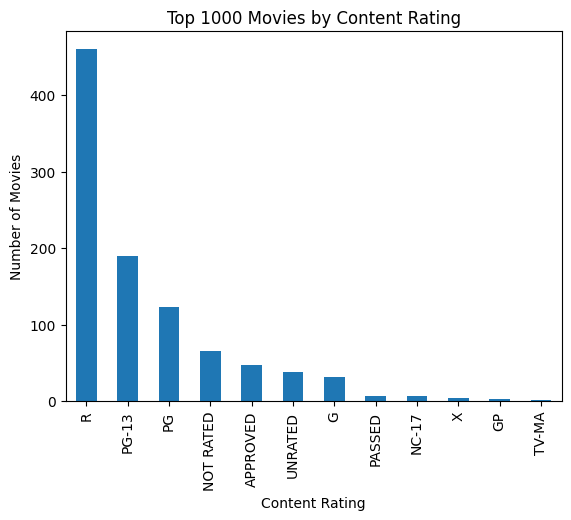

In [12]:
# use a visualization to display that same data, including a title and x and y labels
movies.content_rating.value_counts().plot(kind='bar', title='Top 1000 Movies by Content Rating')
plt.xlabel('Content Rating')
plt.ylabel('Number of Movies')

In [13]:
# convert the following content ratings to "UNRATED": NOT RATED, APPROVED, PASSED, GP
movies.content_rating.replace(['NOT RATED', 'APPROVED', 'PASSED', 'GP'], 'UNRATED', inplace=True)

C:\Users\CharleyHanania\AppData\Local\Temp\ipykernel_36272\4028401049.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  movies.content_rating.replace(['NOT RATED', 'APPROVED', 'PASSED', 'GP'], 'UNRATED', inplace=True)


In [14]:
# convert the following content ratings to "NC-17": X, TV-MA
movies.content_rating.replace(['X', 'TV-MA'], 'NC-17', inplace=True)

In [15]:
# count the number of missing values in each column
movies.isnull().sum()

star_rating       0
title             0
content_rating    3
genre             0
duration          0
actors_list       0
dtype: int64

In [16]:
# if there are missing values: examine them, then fill them in with "reasonable" values
movies[movies.content_rating.isnull()]
movies.content_rating.fillna('UNRATED', inplace=True)

In [17]:
# calculate the average star rating for movies 2 hours or longer,
# and compare that with the average star rating for movies shorter than 2 hours
movies[movies.duration >= 120].star_rating.mean()
movies[movies.duration < 120].star_rating.mean()

7.838666666666665

<Axes: xlabel='duration', ylabel='star_rating'>

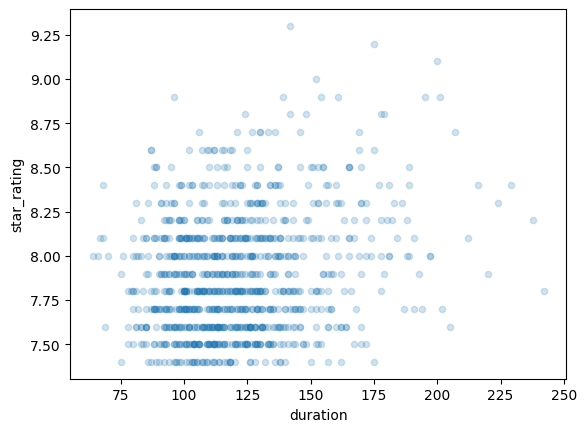

In [18]:
# use a visualization to detect whether there is a relationship between duration and star rating
movies.plot(kind='scatter', x='duration', y='star_rating', alpha=0.2)

In [19]:
# calculate the average duration for each genre
movies.groupby('genre').duration.mean()

genre
Action       126.485294
Adventure    134.840000
Animation     96.596774
Biography    131.844156
Comedy       107.602564
Crime        122.298387
Drama        126.539568
Family       107.500000
Fantasy      112.000000
Film-Noir     97.333333
History       66.000000
Horror       102.517241
Mystery      115.625000
Sci-Fi       109.000000
Thriller     114.200000
Western      136.666667
Name: duration, dtype: float64

In [20]:
'''
ADVANCED LEVEL
'''

'\nADVANCED LEVEL\n'

array([[<Axes: title={'center': 'G'}>, <Axes: title={'center': 'NC-17'}>],
       [<Axes: title={'center': 'PG'}>,
        <Axes: title={'center': 'PG-13'}>],
       [<Axes: title={'center': 'R'}>,
        <Axes: title={'center': 'UNRATED'}>]], dtype=object)

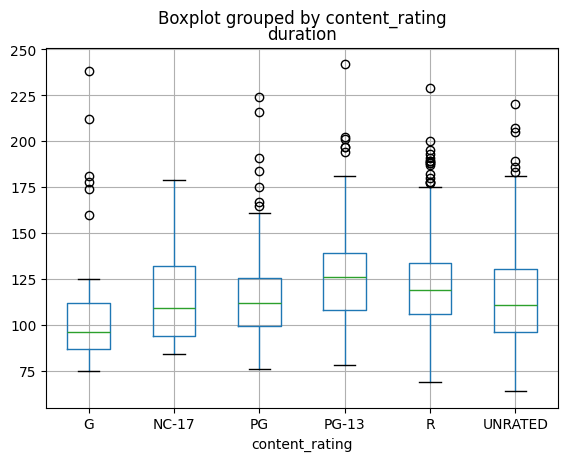

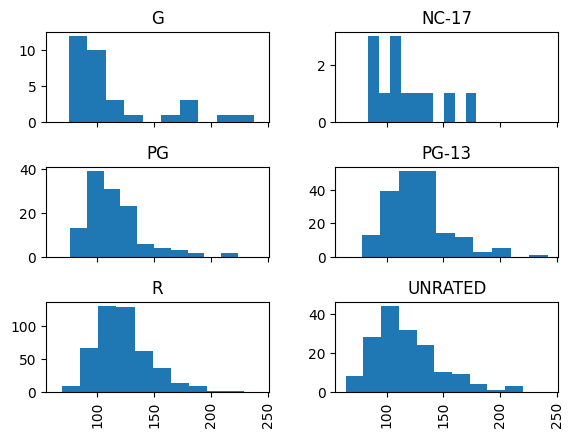

In [21]:
# visualize the relationship between content rating and duration
movies.boxplot(column='duration', by='content_rating')
movies.hist(column='duration', by='content_rating', sharex=True)

In [22]:
# determine the top rated movie (by star rating) for each genre
movies.sort_values('star_rating', ascending=False).groupby('genre').title.first()
movies.groupby('genre').title.first()   # equivalent, since DataFrame is already sorted by star rating

genre
Action                                     The Dark Knight
Adventure    The Lord of the Rings: The Return of the King
Animation                                    Spirited Away
Biography                                 Schindler's List
Comedy                                   Life Is Beautiful
Crime                             The Shawshank Redemption
Drama                                         12 Angry Men
Family                          E.T. the Extra-Terrestrial
Fantasy                          The City of Lost Children
Film-Noir                                    The Third Man
History                                Battleship Potemkin
Horror                                              Psycho
Mystery                                        Rear Window
Sci-Fi                                        Blade Runner
Thriller                                 Shadow of a Doubt
Western                     The Good, the Bad and the Ugly
Name: title, dtype: object

In [23]:
# check if there are multiple movies with the same title, and if so, determine if they are actually duplicates
dupe_titles = movies[movies.title.duplicated()].title
movies[movies.title.isin(dupe_titles)]

,star_rating,title,content_rating,genre,duration,actors_list
466,7.9,The Girl with the Dragon Tattoo,R,Crime,158,"[u'Daniel Craig', u'Rooney Mara', u'Christophe..."
482,7.8,The Girl with the Dragon Tattoo,R,Crime,152,"[u'Michael Nyqvist', u'Noomi Rapace', u'Ewa Fr..."
662,7.7,True Grit,PG-13,Adventure,110,"[u'Jeff Bridges', u'Matt Damon', u'Hailee Stei..."
678,7.7,Les Miserables,PG-13,Drama,158,"[u'Hugh Jackman', u'Russell Crowe', u'Anne Hat..."
703,7.6,Dracula,UNRATED,Horror,85,"[u'Bela Lugosi', u'Helen Chandler', u'David Ma..."
905,7.5,Dracula,R,Horror,128,"[u'Gary Oldman', u'Winona Ryder', u'Anthony Ho..."
924,7.5,Les Miserables,PG-13,Crime,134,"[u'Liam Neeson', u'Geoffrey Rush', u'Uma Thurm..."
936,7.4,True Grit,UNRATED,Adventure,128,"[u'John Wayne', u'Kim Darby', u'Glen Campbell']"


In [24]:
# calculate the average star rating for each genre, but only include genres with at least 10 movies
genre_counts=movies.groupby('genre')['genre'].count()
big_genre=list(genre_counts[genre_counts>10].index)
movies.loc[movies['genre'].isin(big_genre)].groupby('genre')['star_rating'].mean().sort_values()

genre
Horror       7.806897
Comedy       7.822436
Biography    7.862338
Action       7.884559
Drama        7.902518
Animation    7.914516
Crime        7.916935
Adventure    7.933333
Mystery      7.975000
Name: star_rating, dtype: float64

In [25]:
# option 1: manually create a list of relevant genres, then filter using that list
movies.genre.value_counts()
top_genres = ['Drama', 'Comedy', 'Action', 'Crime', 'Biography', 'Adventure', 'Animation', 'Horror', 'Mystery']
movies[movies.genre.isin(top_genres)].groupby('genre').star_rating.mean()

genre
Action       7.884559
Adventure    7.933333
Animation    7.914516
Biography    7.862338
Comedy       7.822436
Crime        7.916935
Drama        7.902518
Horror       7.806897
Mystery      7.975000
Name: star_rating, dtype: float64

In [26]:
# option 2: automatically create a list of relevant genres by saving the value_counts and then filtering
genre_counts = movies.genre.value_counts()
top_genres = genre_counts[genre_counts >= 10].index
movies[movies.genre.isin(top_genres)].groupby('genre').star_rating.mean()

genre
Action       7.884559
Adventure    7.933333
Animation    7.914516
Biography    7.862338
Comedy       7.822436
Crime        7.916935
Drama        7.902518
Horror       7.806897
Mystery      7.975000
Name: star_rating, dtype: float64

In [27]:
# option 3: calculate the average star rating for all genres, then filter using a boolean Series
movies.groupby('genre').star_rating.mean()[movies.genre.value_counts() >= 10]

genre
Action       7.884559
Adventure    7.933333
Animation    7.914516
Biography    7.862338
Comedy       7.822436
Crime        7.916935
Drama        7.902518
Horror       7.806897
Mystery      7.975000
Name: star_rating, dtype: float64

In [28]:
# option 4: aggregate by count and mean, then filter using the count
genre_ratings = movies.groupby('genre').star_rating.agg(['count', 'mean'])
genre_ratings[genre_ratings['count'] >= 10]

,count,mean
genre,,
Action,136,7.884559
Adventure,75,7.933333
Animation,62,7.914516
Biography,77,7.862338
Comedy,156,7.822436
Crime,124,7.916935
Drama,278,7.902518
Horror,29,7.806897
Mystery,16,7.975000


In [29]:
'''
BONUS
'''

'\nBONUS\n'

#### Figure out something "interesting" using the actors data!

In [30]:
# Let's display a list of movies that include Marlon Brando.
movies.loc[movies['actors_list'].str.contains('Marlon Brando')]

,star_rating,title,content_rating,genre,duration,actors_list
1,9.2,The Godfather,R,Crime,175,"[u'Marlon Brando', u'Al Pacino', u'James Caan']"
51,8.5,Apocalypse Now,R,Drama,153,"[u'Martin Sheen', u'Marlon Brando', u'Robert D..."
122,8.3,On the Waterfront,UNRATED,Crime,108,"[u'Marlon Brando', u'Karl Malden', u'Lee J. Co..."
284,8.1,A Streetcar Named Desire,PG,Drama,122,"[u'Vivien Leigh', u'Marlon Brando', u'Kim Hunt..."


In [31]:
# How many movies is Samuel Jackson in?
len(movies.loc[movies['actors_list'].str.contains('Samuel L. Jackson')])

6

In [32]:
# Let's explore a little further.
print(movies.iloc[0]['actors_list'])
# That 'u' is part of the external representation of the string, 
# meaning it's a Unicode string as opposed to a byte string. 

# Let's take a look at the first row of the dataframe, and break up that string of actors into its parts.
line = movies.iloc[0]['actors_list']
import re
line = re.sub("u'", "'", line)
line = re.sub("'", "", line)
line = re.sub('\[', "", line)
line = re.sub("\]", "", line)
actors_list=line.split(', ')
print(actors_list)
print(len(actors_list))
print(actors_list[0])

[u'Tim Robbins', u'Morgan Freeman', u'Bob Gunton']
['Tim Robbins', 'Morgan Freeman', 'Bob Gunton']
3
Tim Robbins


In [33]:
# Now let's write a function that displays all the actors in a clean list.
import re
def actors_cleanlist(row):
    line = row['actors_list']   
    line = re.sub("u'", "'", line)
    line = re.sub("'", "", line)
    line = re.sub('\[', "", line)
    line = re.sub("\]", "", line)
    actors_list=line.split(', ')
    return(actors_list)
actors_cleanlist(movies.iloc[0])

['Tim Robbins', 'Morgan Freeman', 'Bob Gunton']

In [34]:
# Let's create a new column with that list.
movies['cleanlist']=movies.apply(actors_cleanlist, axis=1)
movies.head()

,star_rating,title,content_rating,genre,duration,actors_list,cleanlist
0,9.3,The Shawshank Redemption,R,Crime,142,"[u'Tim Robbins', u'Morgan Freeman', u'Bob Gunt...","[Tim Robbins, Morgan Freeman, Bob Gunton]"
1,9.2,The Godfather,R,Crime,175,"[u'Marlon Brando', u'Al Pacino', u'James Caan']","[Marlon Brando, Al Pacino, James Caan]"
2,9.1,The Godfather: Part II,R,Crime,200,"[u'Al Pacino', u'Robert De Niro', u'Robert Duv...","[Al Pacino, Robert De Niro, Robert Duvall]"
3,9.0,The Dark Knight,PG-13,Action,152,"[u'Christian Bale', u'Heath Ledger', u'Aaron E...","[Christian Bale, Heath Ledger, Aaron Eckhart]"
4,8.9,Pulp Fiction,R,Crime,154,"[u'John Travolta', u'Uma Thurman', u'Samuel L....","[John Travolta, Uma Thurman, Samuel L. Jackson]"


In [35]:
# Okay, let's create columns for actors 1, 2, and 3
movies['actor_0']=movies['cleanlist'].apply(lambda row: row[0])
movies['actor_1']=movies['cleanlist'].apply(lambda row: row[1])
movies['actor_2']=movies['cleanlist'].apply(lambda row: row[2])
movies.head()

,star_rating,title,content_rating,genre,duration,actors_list,cleanlist,actor_0,actor_1,actor_2
0,9.3,The Shawshank Redemption,R,Crime,142,"[u'Tim Robbins', u'Morgan Freeman', u'Bob Gunt...","[Tim Robbins, Morgan Freeman, Bob Gunton]",Tim Robbins,Morgan Freeman,Bob Gunton
1,9.2,The Godfather,R,Crime,175,"[u'Marlon Brando', u'Al Pacino', u'James Caan']","[Marlon Brando, Al Pacino, James Caan]",Marlon Brando,Al Pacino,James Caan
2,9.1,The Godfather: Part II,R,Crime,200,"[u'Al Pacino', u'Robert De Niro', u'Robert Duv...","[Al Pacino, Robert De Niro, Robert Duvall]",Al Pacino,Robert De Niro,Robert Duvall
3,9.0,The Dark Knight,PG-13,Action,152,"[u'Christian Bale', u'Heath Ledger', u'Aaron E...","[Christian Bale, Heath Ledger, Aaron Eckhart]",Christian Bale,Heath Ledger,Aaron Eckhart
4,8.9,Pulp Fiction,R,Crime,154,"[u'John Travolta', u'Uma Thurman', u'Samuel L....","[John Travolta, Uma Thurman, Samuel L. Jackson]",John Travolta,Uma Thurman,Samuel L. Jackson


In [36]:
# Okay, who's the most frequent lead actor?
movies['actor_0'].value_counts().head()

actor_0
Robert De Niro    13
Tom Hanks         12
Clint Eastwood    11
Johnny Depp       10
Al Pacino         10
Name: count, dtype: int64

In [37]:
# Who are the most frequent supporting actors?
print(movies['actor_1'].value_counts().head())
print('\n')
print(movies['actor_2'].value_counts().head())

actor_1
Emma Watson      7
Kate Winslet     6
Matt Damon       6
Geoffrey Rush    5
Grace Kelly      4
Name: count, dtype: int64


actor_2
Rupert Grint          6
Scarlett Johansson    5
Jennifer Connelly     4
Julianne Moore        4
Carrie Fisher         4
Name: count, dtype: int64
